# 4.3 Decision Trees: Understanding Feature Importance

## Objective

Build a Decision Tree classifier on the Nepal earthquake data and compare it to the Logistic Regression model from Lesson 4.2. Unlike logistic regression (which draws a single linear boundary), Decision Trees make predictions by recursively splitting the data — capturing non-linear feature interactions like "old AND mud-foundation buildings are disproportionately at risk."

**The critical idea: bias-variance tradeoff.** A shallow tree underfits (too simple), a deep tree overfits (memorizes noise). We'll tune `max_depth` using a **three-way train/validation/test split** — the validation set chooses the hyperparameter, the test set provides the final honest evaluation.

**Encoding caveat:** trees use OrdinalEncoder (not OneHotEncoder). This is a *limitation*: `foundation_type` categories have no inherent order, so the ordinal encoding places RC at one extreme by accident, not design. Documented in the README.

In [1]:
import os
import sys

def find_project_root(start_dir):
    current = os.path.abspath(start_dir)
    while current != os.path.dirname(current):
        if os.path.exists(os.path.join(current, "pyproject.toml")):
            return current
        current = os.path.dirname(current)
    raise RuntimeError("Project root not found")

PROJECT_ROOT = find_project_root(os.getcwd())
os.chdir(PROJECT_ROOT)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from category_encoders import OrdinalEncoder

from src.duckdb_wrangle import wrangle_nepal_data

print(f"Project root: {PROJECT_ROOT}")
print("All imports successful.")

Project root: /workspaces/Predicting_Earthquake_Damage_Classification_Models
All imports successful.


## 1. Loading the Data

We use the same `wrangle_nepal_data()` pipeline from Lesson 4.1 and the same Gorkha subset (70,836 buildings) as Lesson 4.2 — ensuring a direct, apples-to-apples comparison.

In [2]:
df = wrangle_nepal_data('./data', district_id=4)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"Severe damage rate: {df['severe_damage'].mean():.2%}")

Dataset shape: (70836, 7)
Columns: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type', 'severe_damage']
Severe damage rate: 64.26%


## 2. Defining Features and Target

Target: `severe_damage` (binary).
Features: all other columns (same as Lesson 4.2 for direct comparison).

In [3]:
target = 'severe_damage'
features = [col for col in df.columns if col != target]

X = df[features]
y = df[target]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Features: {features}")

X shape: (70836, 6)
y shape: (70836,)
Features: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type']


## 3. Three-Way Split: Train / Validation / Test

For hyperparameter tuning, we need three sets:

| Set | Size | Purpose |
|---|---|---|
| Training (60%) | ~42,500 | Fit the model |
| Validation (20%) | ~14,100 | Choose `max_depth` |
| Test (20%) | ~14,100 | Final honest evaluation (sealed until the end) |

**Why not two-way?** If we tuned `max_depth` on the test set, we'd be fitting to the test set — data leakage. The validation set provides a "practice exam" separate from the "final exam."

The split is done in two stages:
1. First split off 20% for the test set (final evaluation).
2. Then split the remaining 80% into 75% train / 25% validation (= 60%/20% of the full data).

In [4]:
# First split: 80/20 train_val/test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Second split: 75/25 train/val (= 60/20 of full)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

print(f"Training set:    {X_train.shape[0]:>6} samples ({X_train.shape[0]/len(X):.1%})")
print(f"Validation set:  {X_val.shape[0]:>6} samples ({X_val.shape[0]/len(X):.1%})")
print(f"Test set:        {X_test.shape[0]:>6} samples ({X_test.shape[0]/len(X):.1%})")
print(f"Total:           {len(X):>6} samples")
print()
print(f"Training severe rate:   {y_train.mean():.2%}")
print(f"Validation severe rate: {y_val.mean():.2%}")
print(f"Test severe rate:       {y_test.mean():.2%}")

Training set:     42501 samples (60.0%)
Validation set:   14167 samples (20.0%)
Test set:         14168 samples (20.0%)
Total:            70836 samples

Training severe rate:   64.41%
Validation severe rate: 64.04%
Test severe rate:       64.02%


In [5]:
baseline_acc = y_train.value_counts(normalize=True).max()

print(f"Baseline Accuracy: {baseline_acc:.4f} ({baseline_acc:.2%})")
print(f"Majority class:    {y_train.value_counts().idxmax()}")

Baseline Accuracy: 0.6441 (64.41%)
Majority class:    1


## 4. Initial Decision Tree (max_depth=6)

We fit a Decision Tree with `max_depth=6` as a starting point. The tree learns:
- At each node, find the feature and threshold that most reduce Gini impurity
- Split the data into two groups
- Repeat on each group up to 6 levels deep

**Why `max_depth=6` for the first attempt?** It's a common default — deep enough to capture meaningful patterns, shallow enough to avoid extreme overfitting. In Part 12, we test depths 1-15 and pick the depth that maximizes validation accuracy.

In [6]:
# Initial Decision Tree with max_depth=6
model = Pipeline([
    ('encoder', OrdinalEncoder()),
    ('tree', DecisionTreeClassifier(max_depth=6, random_state=42))
])

model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train))
val_acc = accuracy_score(y_val, model.predict(X_val))

print(f"Training Accuracy:   {train_acc:.4f} ({train_acc:.2%})")
print(f"Validation Accuracy: {val_acc:.4f} ({val_acc:.2%})")
print(f"Baseline Accuracy:   {baseline_acc:.4f} ({baseline_acc:.2%})")
print()
print(f"Train/Val gap:       {train_acc - val_acc:+.4f}")
print(f"Val - Baseline:      {val_acc - baseline_acc:+.4f}")

Training Accuracy:   0.7116 (71.16%)
Validation Accuracy: 0.7099 (70.99%)
Baseline Accuracy:   0.6441 (64.41%)

Train/Val gap:       +0.0017
Val - Baseline:      +0.0658


## 5. Hyperparameter Tuning: The Validation Curve

We train trees at depths 1 through 15 and record both training and validation accuracy at each depth. The goal: find the depth where validation accuracy peaks — the sweet spot between underfitting (depth too small) and overfitting (depth too large).

**Critical rule:** we only look at validation accuracy to choose max_depth. The test set remains sealed — using it to pick hyperparameters would be data leakage.

**What the validation curve shows:**
- **Low depth (1-2)**: train and validation accuracy are both low — the tree is too simple (high bias)
- **Medium depth (4-8)**: validation accuracy peaks — good generalization
- **High depth (12-15)**: training accuracy approaches 99% while validation accuracy falls — the tree memorizes noise (high variance)

In [7]:
# Test max_depth 1 through 15
depths = range(1, 16)
train_accuracies = []
val_accuracies = []

print("Testing max_depth values 1-15...")
for depth in depths:
    model = Pipeline([
        ('encoder', OrdinalEncoder()),
        ('tree', DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    val_acc = accuracy_score(y_val, model.predict(X_val))

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    print(f"  depth={depth:>2} | train={train_acc:.4f} | val={val_acc:.4f} | gap={train_acc - val_acc:+.4f}")

best_depth = list(depths)[val_accuracies.index(max(val_accuracies))]
print()
print(f"Best validation accuracy: {max(val_accuracies):.4f} at depth {best_depth}")

Testing max_depth values 1-15...
  depth= 1 | train=0.6973 | val=0.7011 | gap=-0.0039
  depth= 2 | train=0.6973 | val=0.7011 | gap=-0.0039
  depth= 3 | train=0.7076 | val=0.7122 | gap=-0.0046
  depth= 4 | train=0.7081 | val=0.7133 | gap=-0.0053
  depth= 5 | train=0.7102 | val=0.7143 | gap=-0.0041
  depth= 6 | train=0.7116 | val=0.7099 | gap=+0.0017
  depth= 7 | train=0.7147 | val=0.7134 | gap=+0.0012
  depth= 8 | train=0.7173 | val=0.7138 | gap=+0.0035
  depth= 9 | train=0.7205 | val=0.7134 | gap=+0.0071
  depth=10 | train=0.7241 | val=0.7124 | gap=+0.0117
  depth=11 | train=0.7277 | val=0.7090 | gap=+0.0187
  depth=12 | train=0.7333 | val=0.7100 | gap=+0.0233
  depth=13 | train=0.7397 | val=0.7068 | gap=+0.0329
  depth=14 | train=0.7461 | val=0.7047 | gap=+0.0414
  depth=15 | train=0.7546 | val=0.7045 | gap=+0.0502

Best validation accuracy: 0.7143 at depth 5


## 6. Visualizing the Bias-Variance Tradeoff

The validation curve is the visual signature of the bias-variance tradeoff:

- **Left side (depth 1-2)**: Both training and validation accuracy are low → underfitting (high bias).
- **Middle (depth 3-6)**: Validation accuracy peaks → sweet spot.
- **Right side (depth 10+)**: Training accuracy climbs, validation accuracy falls → overfitting (high variance).

The gap between training and validation curves is the **generalization gap** — the visual measure of overfitting.

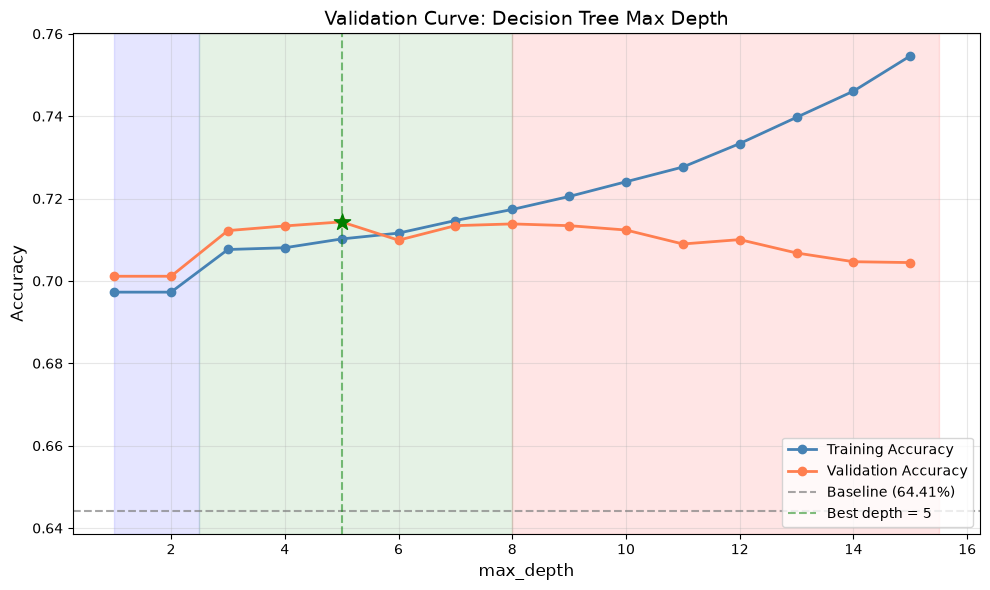

Best max_depth: 5
Best validation accuracy: 0.7143 (71.43%)
Corresponding training accuracy: 0.7102
Train/Val gap at peak: -0.0041


In [8]:
# Cell 14 — Validation curve
best_depth = list(depths)[val_accuracies.index(max(val_accuracies))]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(depths, train_accuracies, 'o-', label='Training Accuracy', color='steelblue', linewidth=2)
ax.plot(depths, val_accuracies, 'o-', label='Validation Accuracy', color='coral', linewidth=2)
ax.axhline(y=baseline_acc, color='gray', linestyle='--', label=f'Baseline ({baseline_acc:.2%})', alpha=0.7)
ax.axvline(x=best_depth, color='green', linestyle='--', alpha=0.5, label=f'Best depth = {best_depth}')

# Highlight the peak
ax.scatter([best_depth], [max(val_accuracies)], color='green', s=150, zorder=5, marker='*')

ax.set_xlabel('max_depth', fontsize=12)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Validation Curve: Decision Tree Max Depth', fontsize=14)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)

# Annotate underfit / optimal / overfit zones
ax.axvspan(1, 2.5, alpha=0.1, color='blue', label='Underfit zone')
ax.axvspan(2.5, 8, alpha=0.1, color='green', label='Optimal zone')
ax.axvspan(8, 15.5, alpha=0.1, color='red', label='Overfit zone')

plt.tight_layout()
plt.show()

print(f"Best max_depth: {best_depth}")
print(f"Best validation accuracy: {max(val_accuracies):.4f} ({max(val_accuracies):.2%})")
print(f"Corresponding training accuracy: {train_accuracies[best_depth - 1]:.4f}")
print(f"Train/Val gap at peak: {train_accuracies[best_depth - 1] - max(val_accuracies):+.4f}")

## 7. Final Model and Test Evaluation

We now train the final Decision Tree with the optimal `max_depth=5` found via the validation curve. We evaluate it on the **test set** (20% of the data) that has been sealed until now.

In [9]:
# Cell 15 — Train final model and evaluate on test set
final_model = Pipeline([
    ('encoder', OrdinalEncoder()),
    ('tree', DecisionTreeClassifier(max_depth=best_depth, random_state=42))
])

final_model.fit(X_train, y_train)

# Evaluate on the sealed test set
test_pred = final_model.predict(X_test)
test_acc = accuracy_score(y_test, test_pred)

print(f"Final Model (max_depth={best_depth}) Performance:")
print(f"Training Accuracy:   {accuracy_score(y_train, final_model.predict(X_train)):.4f}")
print(f"Validation Accuracy: {accuracy_score(y_val, final_model.predict(X_val)):.4f}")
print(f"Test Accuracy:       {test_acc:.4f}")
print(f"Baseline Accuracy:   {baseline_acc:.4f}")
print(f"\nImprovement over baseline: +{test_acc - baseline_acc:.4f} ({(test_acc - baseline_acc)*100:.2f} pp)")

Final Model (max_depth=5) Performance:
Training Accuracy:   0.7102
Validation Accuracy: 0.7143
Test Accuracy:       0.7041
Baseline Accuracy:   0.6441

Improvement over baseline: +0.0599 (5.99 pp)


## 8. Feature Importance

Decision Trees provide a natural measure of feature importance based on **Gini reduction**. We sum the impurity reduction for every split that used a feature, weighted by the number of samples at that node.

- **foundation_type**: Expected to dominate (based on our EDA in Lesson 4.2).
- **age_building / height_ft_pre_eq**: Expected to contribute marginally.
- **district_id**: Should be zero (it's a constant column).

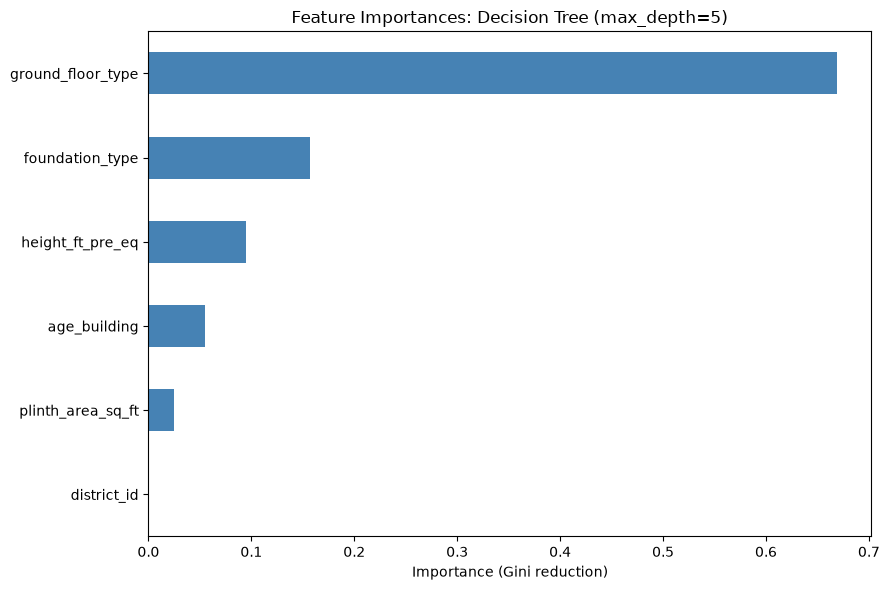

Feature importances (sorted):
ground_floor_type    0.668882
foundation_type      0.156590
height_ft_pre_eq     0.095180
age_building         0.054666
plinth_area_sq_ft    0.024682
district_id          0.000000


In [10]:
# Cell 16 — Feature importance
importances = final_model.named_steps['tree'].feature_importances_
feature_names = final_model.named_steps['encoder'].get_feature_names_out()

feature_importance = pd.Series(importances, index=feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
feature_importance.plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Importance (Gini reduction)')
ax.set_title('Feature Importances: Decision Tree (max_depth=5)')
plt.tight_layout()
plt.show()

print("Feature importances (sorted):")
print(feature_importance.sort_values(ascending=False).to_string())

## 9. Visualizing the Tree Structure

A key advantage of decision trees is interpretability: we can trace exactly how any prediction is made. Below is the first two levels of the tree — enough to see the root split and its immediate children. The full tree has 5 levels (max_depth=5).

**What to look for:**
- The root split: which feature did the tree choose as its very first question?
- The Gini values: how "impure" is the root, and how do children improve?
- The class distributions: what fraction of each node is "severe"?

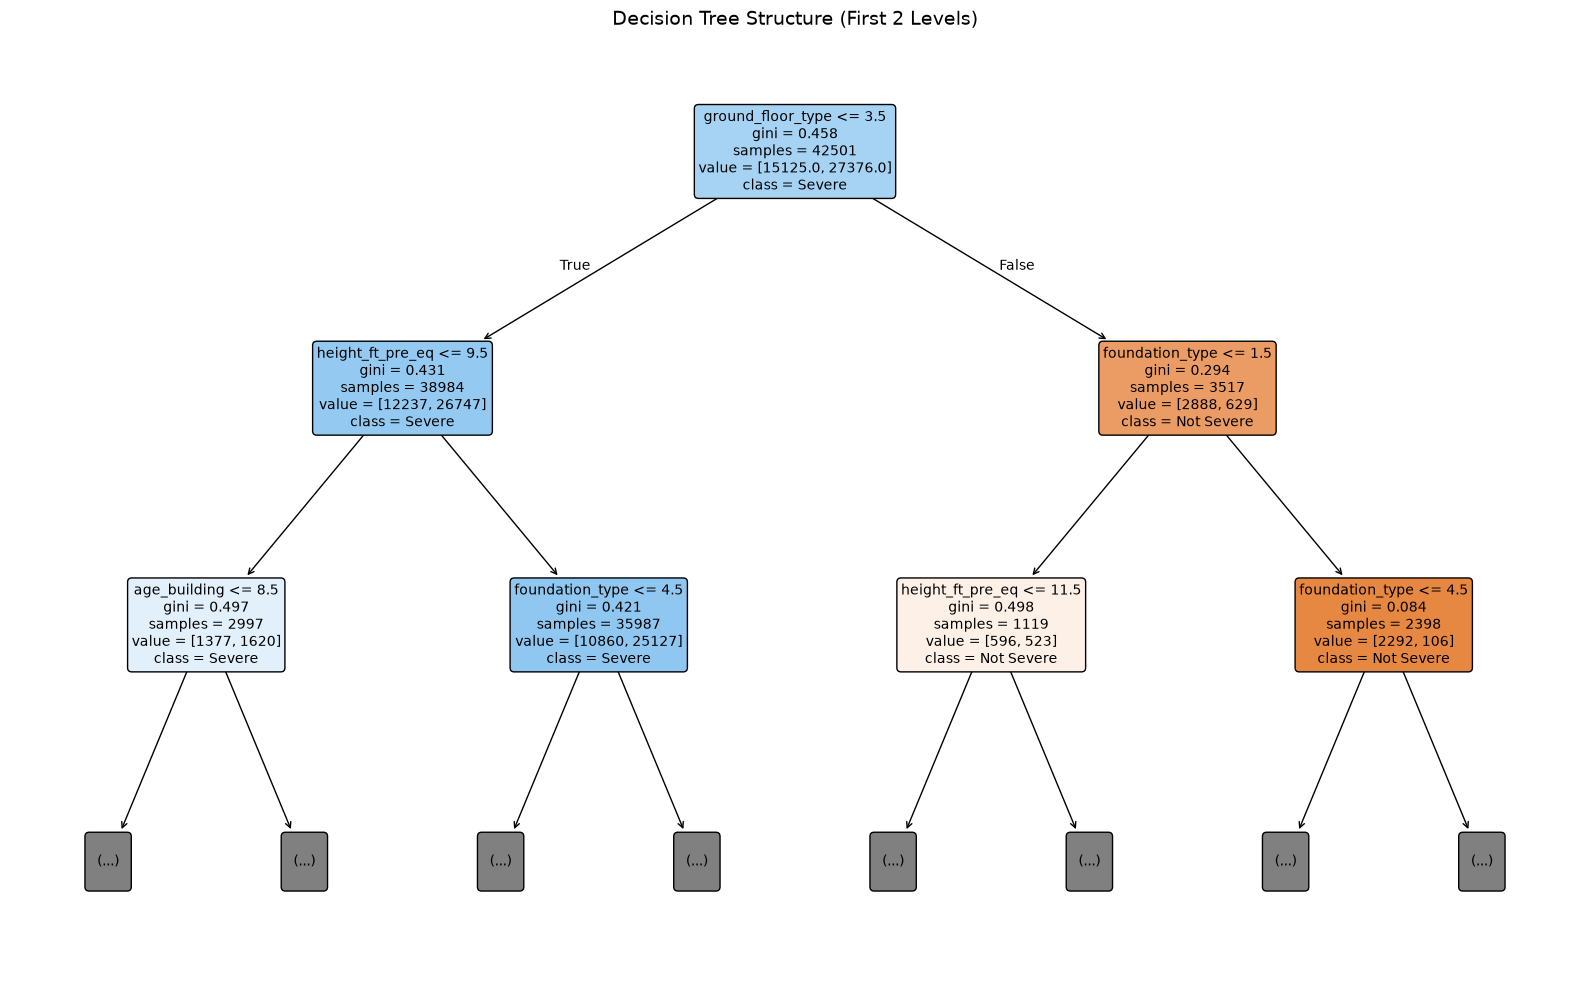

In [11]:
# Cell 17 — Tree visualization
feature_names_encoded = final_model.named_steps['encoder'].get_feature_names_out()

fig, ax = plt.subplots(figsize=(16, 10))
plot_tree(
    final_model.named_steps['tree'],
    feature_names=feature_names_encoded,
    class_names=['Not Severe', 'Severe'],
    filled=True,
    rounded=True,
    max_depth=2,
    ax=ax,
    fontsize=10,
    impurity=True,
    proportion=False,
)
ax.set_title('Decision Tree Structure (First 2 Levels)', fontsize=14)
plt.tight_layout()
plt.show()

## Summary

This lesson built a Decision Tree classifier and compared it to the Logistic Regression model from Lesson 4.2.

### What we built
1. **Three-Way Split**: Separated the data into Train (60%), Validation (20%), and Test (20%) to allow for honest hyperparameter tuning.
2. **Initial Model**: Trained a tree with `max_depth=6` (Validation Accuracy: 70.99%).
3. **Validation Curve**: Tested depths 1-15. Validation accuracy peaked at **depth 5 (71.43%)**. The gap between training and validation widened significantly at depths > 8, demonstrating the bias-variance tradeoff.
4. **Final Model**: Trained at `max_depth=5`. Test Accuracy: **70.41%**.

### Key Findings & Limitations
- **The models are tied**: The Decision Tree (70.41%) and Logistic Regression (70.09%) achieve nearly identical test accuracy. This suggests the underlying pattern is approximately linearly separable (or at least, dominated by a single feature).
- **`ground_floor_type` is the dominant feature**: It accounts for **67% of Gini importance**, dwarfing `foundation_type` (16%). The root split isolates a small subset of "safe" buildings (likely RC-engineered ground floors), which drives most of the predictive power.
- **Weak signal in other features**: `height_ft_pre_eq` (9.5%) and `age_building` (5.5%) contribute marginally. `plinth_area_sq_ft` (2.5%) is barely used. `district_id` was correctly ignored (0.0%) because it's a constant.
- **Pruning prevented overfitting**: A tree at depth 15 achieved 75% training accuracy but only 70% validation accuracy. Limiting depth to 5 kept the train/val gap near zero.

### Next Steps
Lesson 4.4 (Demographics) will return to SQL to join the `household_demographics` table. We will investigate if caste or gender of the household head correlates with severe damage, and whether adding these features improves the model.

## Interpreting the Tree

The tree visualization (first 2 levels) reveals the model's logic:
- **Root Split (`ground_floor_type <= 3.5`)**: This splits the data into a large "vulnerable" group (left) and a small, mostly "safe" group (right, likely RC buildings).
- **Left Branch (`height_ft_pre_eq <= 9.5`)**: For the vulnerable group, the tree checks building height. Shorter buildings are slightly safer.
- **Right Branch (`foundation_type <= 1.5`)**: For the safe group (RC), the tree further refines the prediction based on foundation type to isolate the safest possible buildings.

This hierarchy confirms that structural material (ground floor and foundation) matters more than building age or footprint size.